In [1]:
import numpy as np
import torch
torch.manual_seed(42)
np.random.seed(42)

ydata=np.load('ydata.npy')
sampled_point=np.load('sp.npy')
noise=np.random.normal(0,0.1,sampled_point.shape).astype(np.float32)

sp9=sampled_point+noise

def normalize(x,x_max,x_min):
    # if x_max==x_min:
    #     return np.zeros_like(x)
    return (x-x_min)/(x_max-x_min)*2-1

def denormalize(x,x_max,x_min):
    drange=x_max-x_min
    return (x+1)/2*drange+x_min

spmax=sp9.max(axis=1)
spmin=sp9.min(axis=1)

sp_n=normalize(sp9,spmax[:,None],spmin[:,None])
spmax_max=spmax.max()
spmax_min=spmax.min()
spmin_max=spmin.max()
spmin_min=spmin.min()

spmax_n=normalize(spmax,spmax_max,spmax_min)
spmin_n=normalize(spmin,spmin_max,spmin_min)

embdata=np.concatenate((sp_n,spmax_n[:,np.newaxis],spmin_n[:,np.newaxis]),axis=1)
ydata_norm=normalize(ydata,spmax.reshape(-1,1,1),spmin.reshape(-1,1,1))

In [3]:
array=np.arange(0,ydata_norm.shape[0])
index=np.random.choice(array,10000,replace=False)

v_ydata=ydata_norm[index]
v_emb=embdata[index]
t_ydata=np.delete(ydata_norm,index,0)
t_emb=np.delete(embdata,index,0)

from torch.utils.data import Dataset,DataLoader
class MyDataset(Dataset):
    def __init__(self,embdata,ydata):
        self.embdata=embdata
        self.ydata=ydata
    def __len__(self):
        return len(self.embdata)
    def __getitem__(self,idx):
        return self.embdata[idx],self.ydata[idx]

train_dataset=MyDataset(t_emb,t_ydata)
val_dataset=MyDataset(v_emb,v_ydata)
train_loader=DataLoader(train_dataset,batch_size=32)
val_loader=DataLoader(val_dataset,batch_size=50)

import torch.nn as nn
from tqdm import tqdm
from diffusion_model import DiffusionModel
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')

diffusion=DiffusionModel(
    image_size=(40,240),
    channels=1,
    cond_dim=11,
    timesteps=1000,
    device=device
)

diffusion.load('final_model.pt')

from tqdm import tqdm
diffusion.model.eval()
y_true=np.empty((0,40,240))
y_pred=np.empty((0,40,240))
x_in=np.empty((0,11))
for veb,vyb in tqdm(val_loader):
    x_in=np.concatenate((x_in,veb.numpy()),axis=0)
    y_true=np.concatenate((y_true,vyb.numpy()),axis=0)
    veb=veb.to(device)
    # vyb=vyb.unsqueeze(1).to(device)
    sample=diffusion.generate(veb, num_samples=vyb.size(0))
    y_pred=np.concatenate((y_pred,sample[:,0,:,:]),axis=0)

spmax_vector=denormalize(x_in[:,9],spmax_max,spmax_min).reshape(-1,1,1)
spmin_vector=denormalize(x_in[:,10],spmin_max,spmin_min).reshape(-1,1,1)

true=denormalize(y_true,spmax_vector,spmin_vector)
pred=denormalize(y_pred,spmax_vector,spmin_vector)

def calculate_rmse(matrix1, matrix2):
    error = matrix1 - matrix2    
    # 计算均方误差 (MSE)
    mse = np.mean(error ** 2)    
    # 计算均方根误差 (RMSE)
    rmse = np.sqrt(mse)    
    return rmse
sp9_rmse=[]
for i in range(true.shape[0]):
    rmse=calculate_rmse(true[i],pred[i])
    sp9_rmse.append(rmse)

np.save('sp9_noise_rmse.npy', np.array(sp9_rmse))
print(np.array(sp9_rmse).shape)


Model loaded from final_model.pt


100%|██████████| 200/200 [15:47:40<00:00, 284.30s/it]  


(10000,)


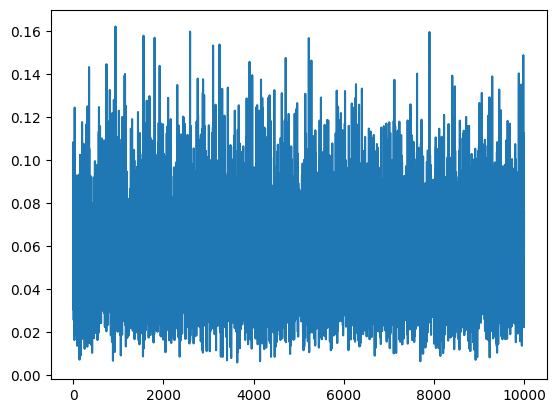

In [4]:
import matplotlib.pyplot as plt
plt.plot(sp9_rmse)

In [5]:
np.mean(sp9_rmse)

np.float64(0.05561698730368884)